### Setup & Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import os

# Path Configuration
TRAIN_CSV = '../data/train/metadata.csv'
TEST_CSV = '../data/test/metadata.csv'
TRAIN_IMG_DIR = '../data/train/'
TEST_IMG_DIR = '../data/test/'

# Loading
train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)

# Tambahkan flag untuk identifikasi
train_df['split'] = 'train'
test_df['split'] = 'test'
df = pd.concat([train_df, test_df], axis=0).reset_index(drop=True)

print(f"Total Sampel: {len(df)}")
df.head()

Total Sampel: 5023


,local_path,image_path,hate_final,appropriate_final,topic,topic_id,ocr,caption,split
0,meme_0.jpg,2375003449526543.jpeg,hate,inappropriate,"individual, gender","Individu, Jenis Kelamin",SUAMI NGEJAR KARIR\nISTRINYA NGEJAR LENDIR,Visual ini menyajikan kontras antara seorang s...,train
1,meme_1.jpg,2304323296603616.jpeg,hate,inappropriate,"individual, political","Individu, Politik","""Godvlan walaupun Rimsvek Omyo itu kurang memu...",Visual ini memadukan ulasan teks informal yang...,train
2,meme_2.jpg,1279082089452362.jpeg,hate,inappropriate,social sub-groups,Kelompok Sosial,"Dewasa bukan soal umur, Tapi tentang pemikiran...",Visual ini memadukan pernyataan kematangan din...,train
3,meme_3.jpg,729319119235607.jpeg,not hate,inappropriate,gender,Jenis Kelamin,kenapa di kamar mu ada baby oil ? padahal di t...,Gambar menampilkan Spongebob mengajukan pertan...,train
4,meme_4.jpg,2283677175334895.jpeg,not hate,appropriate,political,Politik,RELAX edgelord. It's called\nHARI KESAKTIAN PA...,Visual ini menampilkan Superman mengklarifikas...,train


### Label Integrity & Balance (Target Analysis)

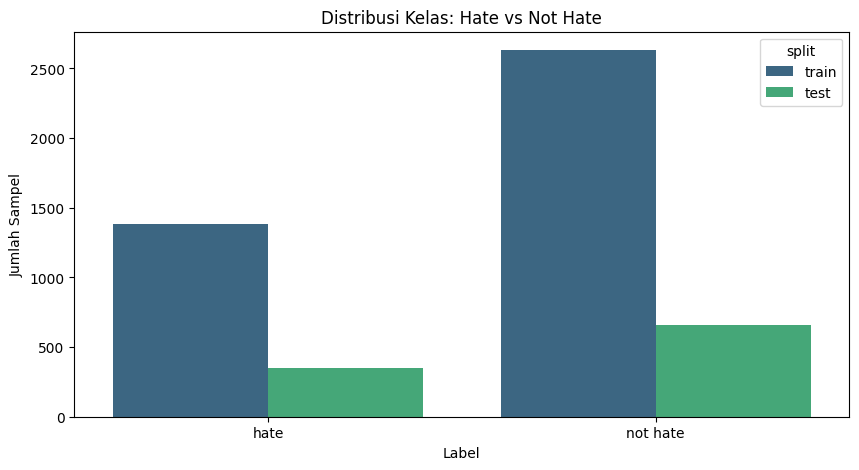

Rasio Kelas Keseluruhan:
hate_final
not hate    65.498706
hate        34.501294
Name: proportion, dtype: float64


In [2]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='hate_final', hue='split', palette='viridis')
plt.title('Distribusi Kelas: Hate vs Not Hate')
plt.xlabel('Label')
plt.ylabel('Jumlah Sampel')
plt.show()

# Persentase Imbalance
print("Rasio Kelas Keseluruhan:")
print(df['hate_final'].value_counts(normalize=True) * 100)

### Analisis Kualitas Teks (OCR vs Caption)

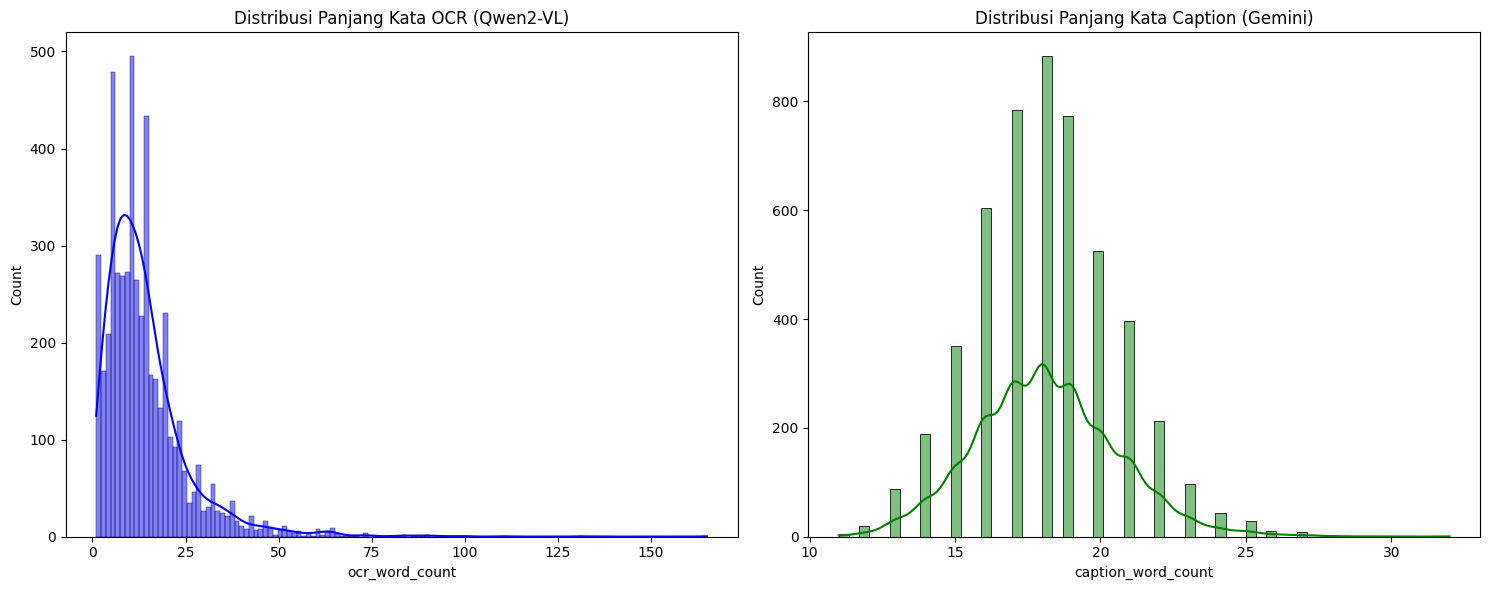

In [3]:
# Kalkulasi panjang kata
df['ocr_word_count'] = df['ocr'].apply(lambda x: len(str(x).split()))
df['caption_word_count'] = df['caption'].apply(lambda x: len(str(x).split()))

# Visualisasi Distribusi Panjang Teks
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

sns.histplot(df['ocr_word_count'], kde=True, ax=ax[0], color='blue')
ax[0].set_title('Distribusi Panjang Kata OCR (Qwen2-VL)')

sns.histplot(df['caption_word_count'], kde=True, ax=ax[1], color='green')
ax[1].set_title('Distribusi Panjang Kata Caption (Gemini)')

plt.tight_layout()
plt.show()

### Topical Bias Analysis

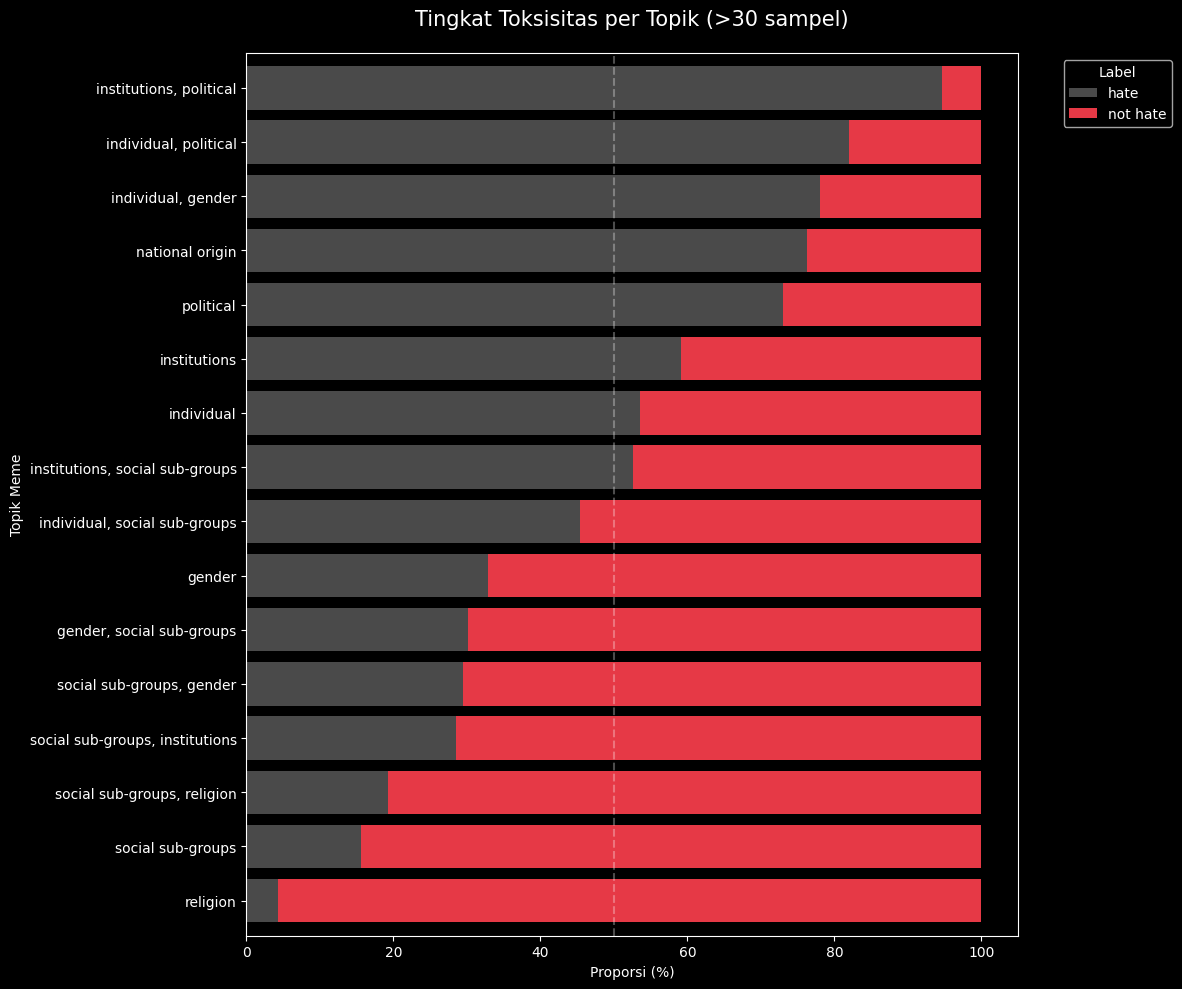

In [5]:
# Filter topik signifikan (>30 sampel)
counts = df['topic'].value_counts()
significant_topics = counts[counts > 30].index
df_filtered = df[df['topic'].isin(significant_topics)].copy()

# Buat crosstab persentase
analysis = pd.crosstab(df_filtered['topic'], df_filtered['hate_final'], normalize='index') * 100

# Cari kolom untuk sorting (hate speech)
target_col = 'hate' if 'hate' in analysis.columns else 1
analysis = analysis.sort_values(by=target_col, ascending=True)

# Visualisasi
plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(12, 10))

# Warna kontras: Abu-abu (Not Hate) vs Merah (Hate)
colors = ['#4A4A4A', '#E63946'] if target_col == 'hate' else ['#E63946', '#4A4A4A']
analysis.plot(kind='barh', stacked=True, ax=ax, color=colors, width=0.8)

ax.set_title('Tingkat Toksisitas per Topik (>30 sampel)', fontsize=15, pad=20)
ax.set_xlabel('Proporsi (%)')
ax.set_ylabel('Topik Meme')
ax.axvline(50, color='white', linestyle='--', alpha=0.3)
ax.legend(title='Label', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

### Image Quality & Dimension Audit

Gambar Non-RGB ditemukan: 0


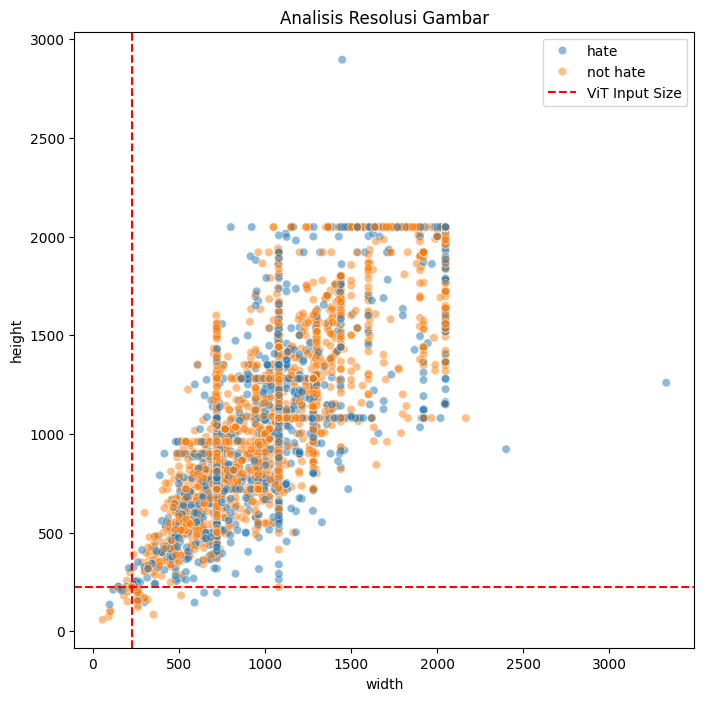

In [ ]:
def get_image_info(row):
    path = os.path.join(TRAIN_IMG_DIR if row['split']=='train' else TEST_IMG_DIR, row['local_path'])
    try:
        with Image.open(path) as img:
            return img.size[0], img.size[1], img.mode
    except:
        return None, None, None

# Sample 1000 data untuk efisiensi jika perlu, atau semua jika kuat
df[['width', 'height', 'mode']] = df.apply(get_image_info, axis=1, result_type='expand')

# Cek gambar yang bukan RGB (misalnya Grayscale atau CMYK)
non_rgb = df[df['mode'] != 'RGB']
print(f"Gambar Non-RGB ditemukan: {len(non_rgb)}")

# Visualisasi Scatter Resolution
plt.figure(figsize=(8, 8))
sns.scatterplot(data=df, x='width', y='height', hue='hate_final', alpha=0.5)
plt.axvline(224, color='red', linestyle='--', label='ViT Input Size')
plt.axhline(224, color='red', linestyle='--')
plt.title('Analisis Resolusi Gambar')
plt.legend()
plt.show()

### Audit Duplikasi & Missing Values

In [6]:
# Cek Missing Values
print("Missing Values:\n", df[['ocr', 'caption', 'hate_final']].isnull().sum())

# Cek Duplikasi Gambar (berdasarkan path asli jika ada)
duplicate_images = df.duplicated(subset=['image_path']).sum()
print(f"Duplikasi file gambar: {duplicate_images}")

# Cek Duplikasi Teks (OCR) - Sering terjadi pada template meme yang sama
duplicate_texts = df.duplicated(subset=['ocr']).sum()
print(f"Duplikasi teks OCR: {duplicate_texts}")

Missing Values:
 ocr           0
caption       0
hate_final    0
dtype: int64
Duplikasi file gambar: 0
Duplikasi teks OCR: 44


### Analisis Kata Kunci (Lexical Audit)

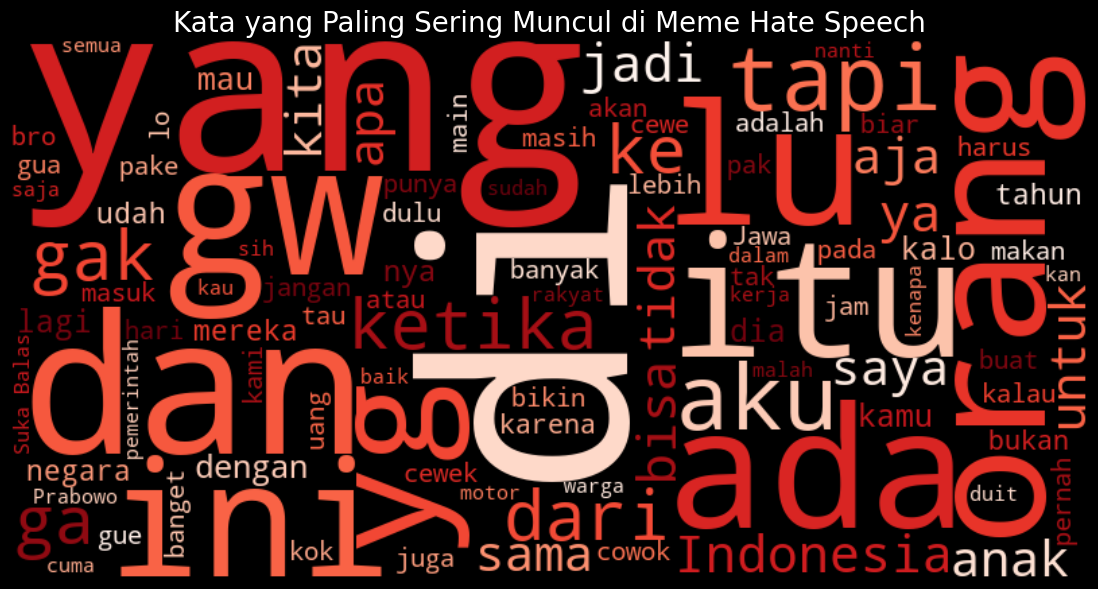

In [9]:
from wordcloud import WordCloud

# Ambil teks ocr hanya untuk label 'hate'
hate_text = " ".join(df[df['hate_final'] == 'hate']['ocr'].astype(str))

wordcloud = WordCloud(width=800, height=400, background_color='black', 
                      colormap='Reds', max_words=100).generate(hate_text)

plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Kata yang Paling Sering Muncul di Meme Hate Speech', fontsize=20)
plt.show()

# Kesimpulan Audit Data & Strategi Pengembangan

---

## Insight Utama (Hasil Audit)

### 1. Keseimbangan Kelas & Stratifikasi
* Kondisi: Dataset memiliki rasio 65:35 (Not Hate : Hate), yang tergolong moderate imbalance.
* Status: Pembagian data (train-test split) sudah dilakukan dengan sangat baik dan konsisten menggunakan stratifikasi.
* Risiko: Model berpotensi bias ke kelas Not Hate. Oleh karena itu, metrik akurasi saja tidak cukup representatif dan bisa menyesatkan.

### 2. Sinergi Teks (OCR vs Caption)
* Kondisi: OCR (Qwen2-VL): cenderung pendek (5–15 kata), informal, dan penuh slang.
* Caption (Gemini): lebih panjang (18–20 kata), deskriptif, dan formal.
* Status: Kombinasi ini sangat kuat. OCR menangkap “emosi mentah”, sementara caption memberikan konteks visual yang lebih lengkap.
* Risiko: Banyaknya slang (gw, lo, ga) dapat menurunkan performa model NLP umum. Oleh karena itu, penggunaan IndoBERTweet menjadi sangat penting.

### 3. Bias Topik (Political Trap)
* Kondisi: 
    * Topik Politik hampir 95% berlabel Hate Speech.
    * Topik Religion justru memiliki tingkat toksisitas yang rendah.
* Risiko: Model bisa mengalami shortcut learning, misalnya langsung mengasosiasikan wajah politisi dengan label hate.
→ Perlu pendekatan XAI untuk memastikan model benar-benar memahami konteks teks, bukan sekadar pola visual.

### 4. Kualitas Visual
* Kondisi: Mayoritas gambar memiliki resolusi tinggi (>1000px), jauh di atas kebutuhan standar model seperti ViT (224px).
* Status: Sangat baik untuk ekstraksi fitur.
* Risiko: Proses resize dapat menghilangkan detail kecil (misalnya teks pada meme) jika tidak dilakukan dengan metode yang tepat.